<a href="https://colab.research.google.com/github/trinidadperea/clasificador-pasteleria/blob/main/FinalIA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
   !pip install gradio -q
   !wget -q http://data.vision.ee.ethz.ch/cvl/food-101.tar.gz
   !tar -xzf food-101.tar.gz

In [ ]:
import os, random, shutil
random.seed(42)

CLASES = ["chocolate_cake", "apple_pie", "cup_cakes", "macarons", "donuts"]
BASE = "food-101"

def leer(nombre):
    return [l.strip() for l in open(f"{BASE}/meta/{nombre}.txt")]

train_all, test_all = leer("train"), leer("test")

def copiar(rutas, split, clase):
    destino = f"dataset/{split}/{clase}"
    os.makedirs(destino, exist_ok=True)
    for r in rutas:                      # r = "apple_pie/1005649"
        shutil.copy(f"{BASE}/images/{r}.jpg", destino)

for clase in CLASES:
    del_train = [r for r in train_all if r.startswith(clase + "/")]
    random.shuffle(del_train)
    corte = int(len(del_train) * 0.85)
    copiar(del_train[:corte], "train", clase)   # ~637 imágenes
    copiar(del_train[corte:], "val", clase)     # ~113 imágenes
    copiar([r for r in test_all if r.startswith(clase + "/")], "test", clase)  # 250

In [ ]:
for split in ["train", "val", "test"]:
    for c in CLASES:
        print(split, c, len(os.listdir(f"dataset/{split}/{c}")))

train chocolate_cake 637
train apple_pie 637
train cup_cakes 637
train macarons 637
train donuts 637
val chocolate_cake 113
val apple_pie 113
val cup_cakes 113
val macarons 113
val donuts 113
test chocolate_cake 250
test apple_pie 250
test cup_cakes 250
test macarons 250
test donuts 250


In [ ]:
nombres = {
    "apple_pie": "Tarta", "chocolate_cake": "Torta",
    "cup_cakes": "Cupcake", "donuts": "Dona", "macarons": "Macaron",
}

def predecir(img):
    img = tf.image.resize(img, (224, 224))
    probs = model.predict(img[None, ...], verbose=0)[0]
    return {nombres[class_names[i]]: float(probs[i]) for i in range(len(class_names))}

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

IMG = (224, 224)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/train", image_size=IMG, batch_size=BATCH, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/val", image_size=IMG, batch_size=BATCH, shuffle=False)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/test", image_size=IMG, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
print(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Found 3185 files belonging to 5 classes.
Found 565 files belonging to 5 classes.
Found 1250 files belonging to 5 classes.
['apple_pie', 'chocolate_cake', 'cup_cakes', 'donuts', 'macarons']


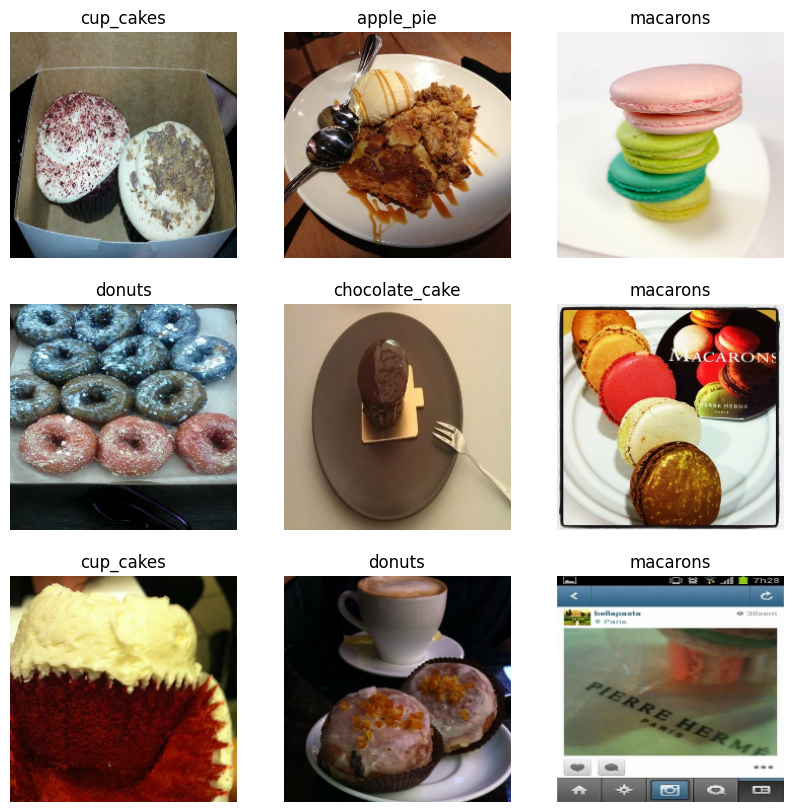

In [ ]:
plt.figure(figsize=(10, 10))
for imgs, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

In [ ]:
from tensorflow.keras import layers, models

cnn_scratch = models.Sequential([
    layers.Input((224, 224, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
])
cnn_scratch.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])

hist_scratch = cnn_scratch.fit(train_ds, validation_data=val_ds, epochs=15)

Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 28s 179ms/step - accuracy: 0.2920 - loss: 1.6247 - val_accuracy: 0.3876 - val_loss: 1.3957
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.3965 - loss: 1.4155 - val_accuracy: 0.4230 - val_loss: 1.3583
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.4311 - loss: 1.3540 - val_accuracy: 0.4124 - val_loss: 1.3444
Epoch 4/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.4819 - loss: 1.2625 - val_accuracy: 0.4566 - val_loss: 1.3030
Epoch 5/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.5165 - loss: 1.1712 - val_accuracy: 0.4460 - val_loss: 1.3508
Epoch 6/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.5727 - loss: 1.0553 - val_accuracy: 0.4319 - val_loss: 1.4613
Epoch 7/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.6254 - loss: 0.9322 - val_accuracy: 0.4248 - val_loss: 1.5611
Epoch 8/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.6939 - loss: 0.7973 - val_ac

In [ ]:
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
])

base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False   # congelado

inputs = tf.keras.Input((224, 224, 3))
x = augment(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

es = tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)
hist_tl = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=[es])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 17s 85ms/step - accuracy: 0.6232 - loss: 0.9951 - val_accuracy: 0.7912 - val_loss: 0.5817
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - accuracy: 0.7761 - loss: 0.6218 - val_accuracy: 0.8177 - val_loss: 0.5236
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - accuracy: 0.8047 - loss: 0.5409 - val_accuracy: 0.8301 - val_loss: 0.4935
Epoch 4/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - accuracy: 0.8144 - loss: 0.5056 - val_accuracy: 0.8283 - val_loss: 0.4847
Epoch 5/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - accuracy: 0.8370 - loss: 0.4676 - val_accuracy: 0.8425 - val_loss: 0.4701
Epoch 6/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.8370 - loss: 0.4515 - val_accuracy: 0.8265 - val_loss: 0.4922
Epoch 7/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - accuracy: 0.8509 - loss: 0.4215 - val_accuracy: 0.8442 - val_loss: 0.4744
Epoch 8/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms

In [ ]:
base.trainable = True
for layer in base.layers[:-30]:      # congelamos todas menos las últimas 30
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),   # learning rate MUY bajo
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

es_ft = tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
hist_ft = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[es_ft])

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 101ms/step - accuracy: 0.7702 - loss: 0.6466 - val_accuracy: 0.8372 - val_loss: 0.4744
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.8038 - loss: 0.5385 - val_accuracy: 0.8442 - val_loss: 0.4777
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 85ms/step - accuracy: 0.8257 - loss: 0.4739 - val_accuracy: 0.8389 - val_loss: 0.4835
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 83ms/step - accuracy: 0.8392 - loss: 0.4514 - val_accuracy: 0.8407 - val_loss: 0.4801


CNN desde cero:                 0.434
Transfer learning + fine-tuning: 0.878
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step
                precision    recall  f1-score   support

     apple_pie       0.91      0.89      0.90       250
chocolate_cake       0.91      0.82      0.86       250
     cup_cakes       0.77      0.92      0.84       250
        donuts       0.88      0.83      0.85       250
      macarons       0.94      0.92      0.93       250

      accuracy                           0.88      1250
     macro avg       0.88      0.88      0.88      1250
  weighted avg       0.88      0.88      0.88      1250



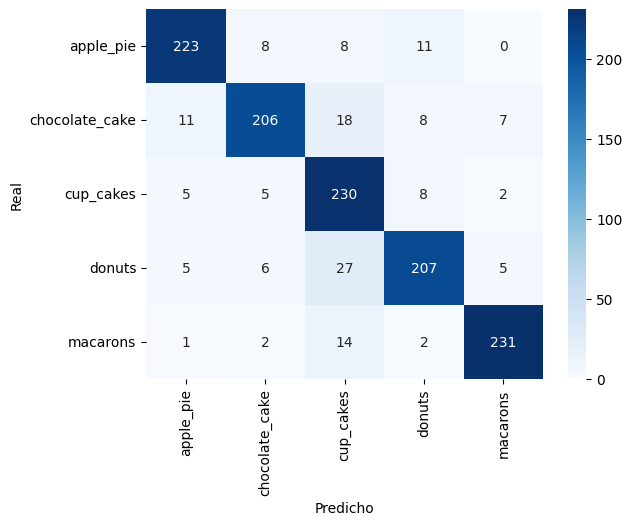

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Comparativo
loss_s, acc_s = cnn_scratch.evaluate(test_ds, verbose=0)
loss_f, acc_f = model.evaluate(test_ds, verbose=0)
print(f"CNN desde cero:                 {acc_s:.3f}")
print(f"Transfer learning + fine-tuning: {acc_f:.3f}")

# Métricas por clase del modelo final
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names))

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names,
            yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicho"); plt.ylabel("Real")
plt.show()

['Tarta', 'Torta', 'Cupcake', 'Dona', 'Macaron']
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step
              precision    recall  f1-score   support

       Tarta       0.91      0.89      0.90       250
       Torta       0.91      0.82      0.86       250
     Cupcake       0.77      0.92      0.84       250
        Dona       0.88      0.83      0.85       250
     Macaron       0.94      0.92      0.93       250

    accuracy                           0.88      1250
   macro avg       0.88      0.88      0.88      1250
weighted avg       0.88      0.88      0.88      1250



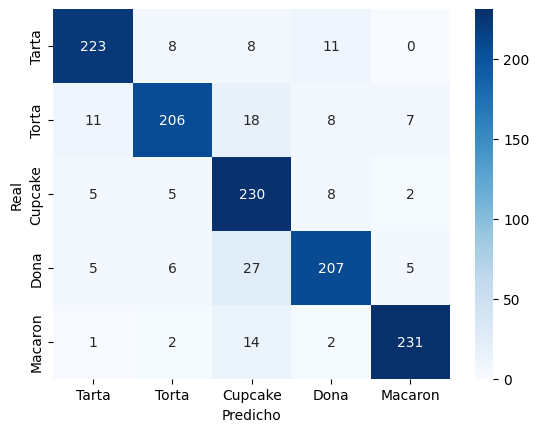

In [ ]:
# Traducción de las clases (el orden sale de class_names, no lo escribas a mano)
traduccion = {
    "apple_pie": "Tarta",
    "chocolate_cake": "Torta",
    "cup_cakes": "Cupcake",
    "donuts": "Dona",
    "macarons": "Macaron",
}
nombres_es = [traduccion[c] for c in class_names]
print(nombres_es)   # ['Tarta', 'Torta', 'Cupcake', 'Dona', 'Macaron']

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=nombres_es))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=nombres_es,
            yticklabels=nombres_es, cmap="Blues")
plt.xlabel("Predicho"); plt.ylabel("Real")
plt.show()

In [ ]:
def predecir(img):
    img = tf.image.resize(img, (224, 224))
    probs = model.predict(img[None, ...], verbose=0)[0]
    return {nombres_es[i]: float(probs[i]) for i in range(len(nombres_es))}

In [ ]:
print("CNN desde cero   | val :", cnn_scratch.evaluate(val_ds, verbose=0)[1])
print("TL congelada     | val :", max(hist_tl.history["val_accuracy"]))
print("TL + fine-tuning | val :", model.evaluate(val_ds, verbose=0)[1])
print("CNN desde cero   | test:", cnn_scratch.evaluate(test_ds, verbose=0)[1])
print("TL + fine-tuning | test:", model.evaluate(test_ds, verbose=0)[1])

CNN desde cero   | val : 0.42300885915756226
TL congelada     | val : 0.8442477583885193
TL + fine-tuning | val : 0.8371681571006775
CNN desde cero   | test: 0.4336000084877014
TL + fine-tuning | test: 0.8776000142097473


In [ ]:
print("CNN desde cero   | train:", hist_scratch.history["accuracy"][-1])
print("TL congelada     | train:", hist_tl.history["accuracy"][-1])
print("TL + fine-tuning | train:", hist_ft.history["accuracy"][-1])

CNN desde cero   | train: 0.8784929513931274
TL congelada     | train: 0.8549450635910034
TL + fine-tuning | train: 0.8392464518547058


In [ ]:
import json
from google.colab import drive, files

model.save("modelo_pasteleria.keras")
json.dump({"class_names": class_names, "traduccion": traduccion},
          open("clases.json", "w"), ensure_ascii=False)

# Copia en Drive (te pide autorización)
drive.mount("/content/drive")
!cp modelo_pasteleria.keras clases.json /content/drive/MyDrive/

# Descarga a tu compu
files.download("modelo_pasteleria.keras")
files.download("clases.json")

Mounted at /content/drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

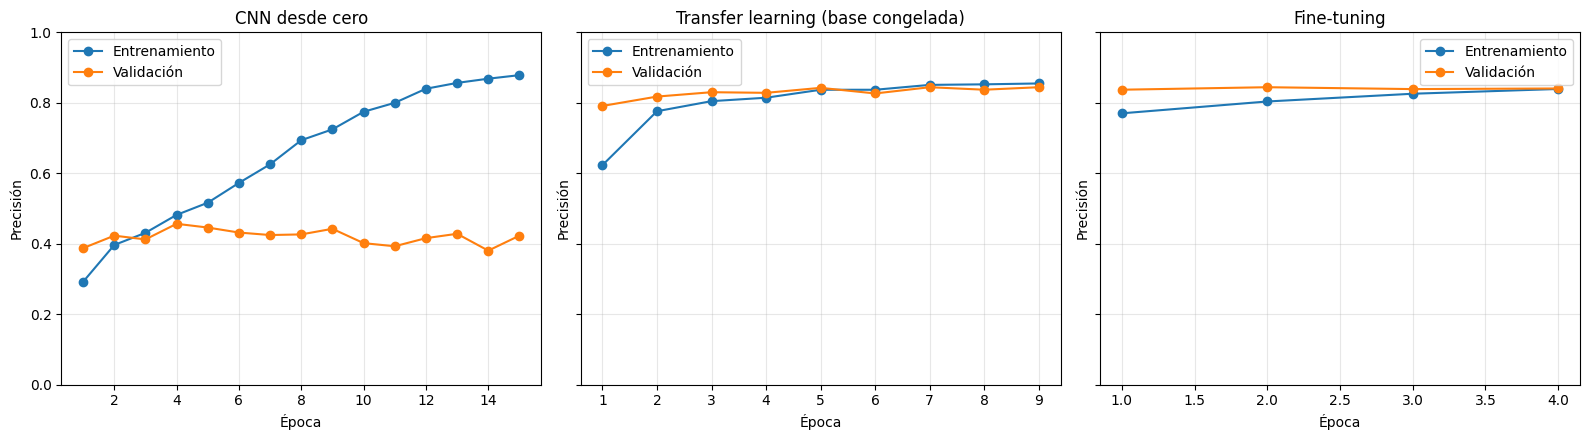

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

def graficar(ax, hist, titulo, metrica="accuracy", etiqueta_y="Precisión"):
    epocas = range(1, len(hist.history[metrica]) + 1)
    ax.plot(epocas, hist.history[metrica], marker="o", label="Entrenamiento")
    ax.plot(epocas, hist.history["val_" + metrica], marker="o", label="Validación")
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_ylabel(etiqueta_y)
    ax.grid(alpha=0.3)
    ax.legend()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
graficar(axes[0], hist_scratch, "CNN desde cero")
graficar(axes[1], hist_tl, "Transfer learning (base congelada)")
graficar(axes[2], hist_ft, "Fine-tuning")
axes[0].set_ylim(0, 1)
plt.tight_layout()
plt.savefig("curvas_precision.png", dpi=200, bbox_inches="tight")
plt.show()
files.download("curvas_precision.png")

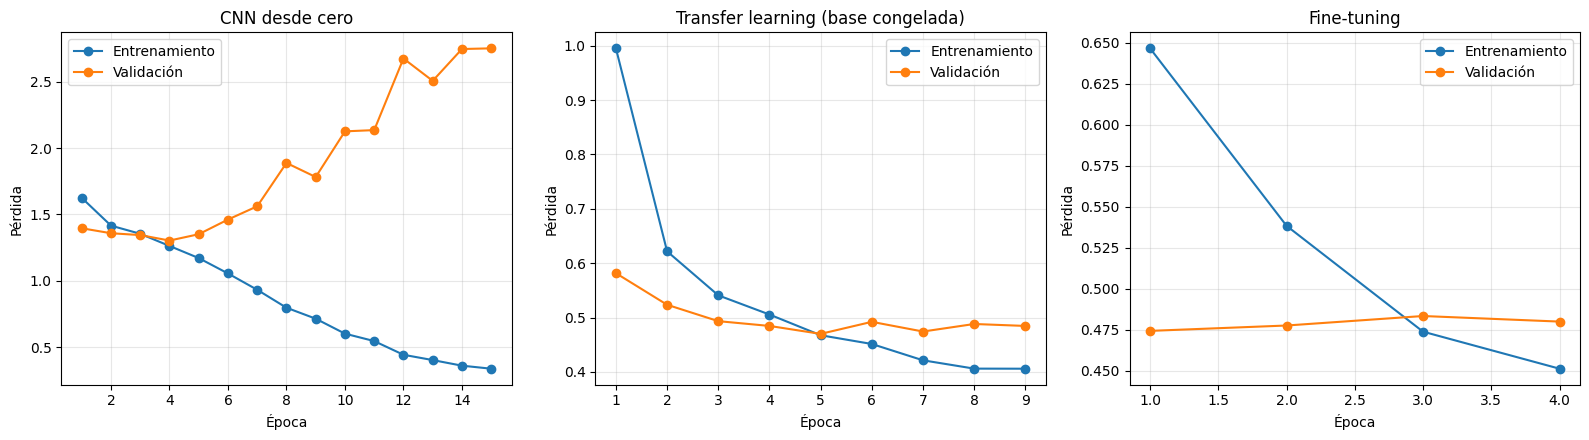

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
graficar(axes[0], hist_scratch, "CNN desde cero", "loss", "Pérdida")
graficar(axes[1], hist_tl, "Transfer learning (base congelada)", "loss", "Pérdida")
graficar(axes[2], hist_ft, "Fine-tuning", "loss", "Pérdida")
plt.tight_layout()
plt.savefig("curvas_perdida.png", dpi=200, bbox_inches="tight")
plt.show()
files.download("curvas_perdida.png")

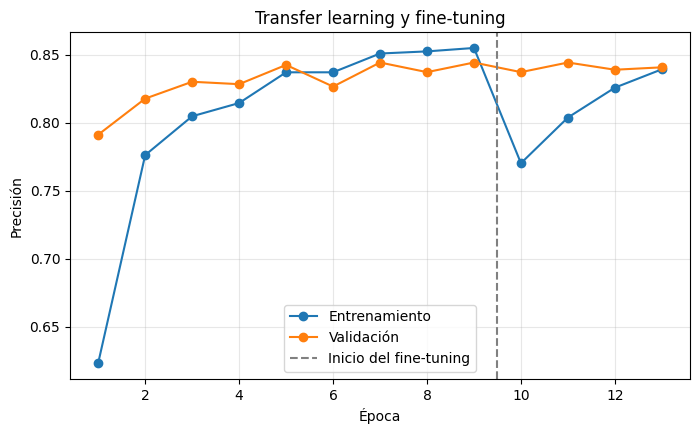

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
acc = hist_tl.history["accuracy"] + hist_ft.history["accuracy"]
val = hist_tl.history["val_accuracy"] + hist_ft.history["val_accuracy"]
corte = len(hist_tl.history["accuracy"])

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(acc) + 1), acc, marker="o", label="Entrenamiento")
plt.plot(range(1, len(val) + 1), val, marker="o", label="Validación")
plt.axvline(corte + 0.5, color="gray", linestyle="--", label="Inicio del fine-tuning")
plt.xlabel("Época"); plt.ylabel("Precisión")
plt.title("Transfer learning y fine-tuning")
plt.grid(alpha=0.3); plt.legend()
plt.savefig("curvas_tl_ft.png", dpi=200, bbox_inches="tight")
plt.show()
files.download("curvas_tl_ft.png")

In [ ]:
import gradio as gr

def predecir(img):
    img = tf.image.resize(img, (224, 224))
    probs = model.predict(img[None, ...], verbose=0)[0]
    return {nombres_es[i]: float(probs[i]) for i in range(len(nombres_es))}

demo = gr.Interface(
    fn=predecir,
    inputs=gr.Image(label="Subí una foto"),
    outputs=gr.Label(num_top_classes=5, label="Predicción"),
    title="Clasificador de pastelería",
    description="Subí una foto de una tarta, torta, cupcake, dona o macaron.",
)
demo.launch(share=True, debug=True)

In [ ]:
import json
import tensorflow as tf
import gradio as gr
from google.colab import drive

drive.mount("/content/drive")

# Cargar el modelo y las clases guardadas en el paso 9
model = tf.keras.models.load_model("/content/drive/MyDrive/modelo_pasteleria.keras")
datos = json.load(open("/content/drive/MyDrive/clases.json", encoding="utf-8"))
class_names, traduccion = datos["class_names"], datos["traduccion"]
nombres_es = [traduccion[c] for c in class_names]

def predecir(img):
    img = tf.image.resize(img, (224, 224))
    probs = model.predict(img[None, ...], verbose=0)[0]
    return {nombres_es[i]: float(probs[i]) for i in range(len(nombres_es))}

demo = gr.Interface(
    fn=predecir,
    inputs=gr.Image(label="Subí una foto"),
    outputs=gr.Label(num_top_classes=5, label="Predicción"),
    title="Clasificador de pastelería",
    description="Subí una foto de una tarta, torta, cupcake, dona o macaron.",
)
demo.launch(share=True, debug=True)

Mounted at /content/drive
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://5677cc4f509bbb7faf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
